# Chapter 2: Simple Linear Regression excercise

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

## 2.1 Introduction & Motivation

Now that you have learned about linear regression, how to use it and how to evaluate, it's time to put this into practice!
We will be looking at a dataset containing data about advertisement budget and sales. We will be trying to see if there are any correlations and if we can predict these.

## 2.2 Problem setting

A company called Contoso is spending a certain amount of budget on advertising each month. They are keeping all this data in a single dataset which displays sales (in thousands of units) for a particular product as well as advertising budgets (in thousands of dollars) for TV, radio, and newspaper media that month.

## 2.3 Model

Go to canvas and donload the file "Advertising.csv" from module 2. This data contains the required dataset.

In [2]:
df = pd.read_csv("Advertising.csv")
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [3]:
df.dtypes

TV           float64
radio        float64
newspaper    float64
sales        float64
dtype: object

In [4]:
df.isna().sum()

TV           0
radio        0
newspaper    0
sales        0
dtype: int64

##### Question 1: Have a look at the columns and data of this dataset. What variables would you want to predict? What variables would you like to base your prediction on?

##### Question 2: Without plotting the data on a graph, think about the real-life facts behind this data. Would you expect linear regression make sense for the required predictions? Why (not)?

Before we train this new model, we first want to create a column where all our information is stored. We will call this column 'total_spent'.

Since we are working with an actual dataset, we also want to split our data. in a train and a test set. This ensure we can properly evaluate our model and test in on data it has never seen before.

In [71]:
df['total_spent'] = df['TV'] + df['radio'] + df['newspaper']

X = df['total_spent'].to_numpy().reshape(-1, 1) # => Transform into sub-arrays, the model must have sub-arrays.
y = df['sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

##### Question 3: Notice the two parameters called "test_size" and "random_state". "test_size" is required while "random_state" is an optional parameter. Read the sklearn documentation to know more about them. What do these variables mean? Are there any contraineds on them or can you put whatever you want? What would happen if you change the numers? What would happen if you drop the "random_state" parameter? Can you think of any scenario's where you would do so?

Now that you have prepared your data it's time to train the model. Make sure to only use the training data!

test_size = the percentage of data you allocate to testing. In this case 30% of all data is allocated for testing.

random_state = You choose that 30% of your data will be allocated for testing, but what data will be taken exactly? You don't want to take the last 30% of that data. You need the data to be chosen randomly. The random state number is a seed: base your randomness based on this number. This works like minecraft lol: different seeds pick different rows, just randomly. The same seed always takes the same rows: so using the same seed = the same results.

In [72]:
model = LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

##### Question 4:  Plot a graph to show the amount of sales in function of the total amount spent on advertising. Draw a line using Beta 0 and Beta 1 to show our model. Does this confirm/deny your earlier assumptions about whether or not to choose linear regression?

In [ ]:
Intercept = model.intercept_
Slope = model.coef_[0]

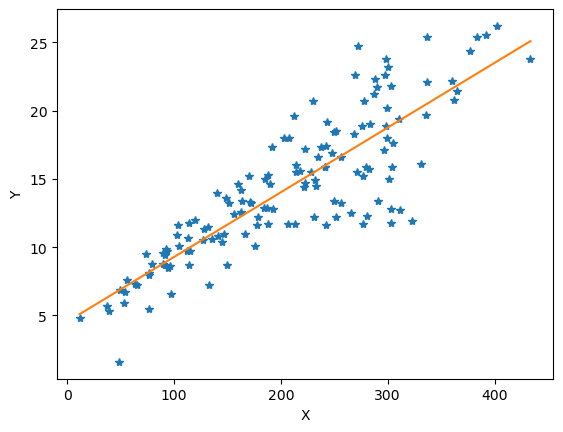

In [20]:
min_pt = X.min() * model.coef_[0] + Intercept
max_pt = X.max() * model.coef_[0] + Intercept
plt.plot(X_train, y_train, '*')
plt.plot([X.min(), X.max()], [min_pt, max_pt])
plt.xlabel("X")
plt.ylabel("Y")

plt.show()

## 2.4 Model Evaluation

Now it's time to evaluate this model! To do so, calculate the $R^2$ value of our model.

##### Question 5: Interpret the $R^2$ score. Is our model any good?

In [21]:
print("The R2 score of this beautiful model is:", model.score(X_train, y_train))

The R2 score of this beautiful model is: 0.73228658313651


The $R^2$ value is not the only value that evaluates our model. Another interesting value to look at is the $MSE$.

##### Question 6: Calculate the MSE. Remember that we kept some test data on the side exactly for this purpose!

In [73]:
y_pred = model.predict(X_test)
y_pred

array([12.58753755, 18.17926732, 12.54488876, 14.44512913,  7.30382678,
        7.27539426, 19.10806312, 16.44014459, 11.70612929, 18.35933998,
        8.81548932, 13.71062225, 15.86201659, 19.1507119 , 18.98011676,
        8.85813811, 18.089231  ,  9.49313115,  8.33213641, 18.64840397,
        7.22800672, 16.32641449, 21.96079305, 21.53904394,  8.29422638,
       15.79567404, 19.8520475 ,  9.97648406, 13.69640599, 10.81524353,
       10.45509822, 18.68157525, 11.57818293,  8.27053261, 16.34536951,
       10.63990963, 10.45983698,  9.62107751,  8.98608447, 12.4785462 ,
       14.89057201, 12.51171748, 11.64452549,  8.8486606 , 10.48353075,
        9.65898754,  6.65935623, 18.42094378, 16.38801829, 18.56784515,
       10.64938714, 15.99470171, 19.31182954, 11.04744248, 15.13698722,
        5.55522654, 19.5013797 ,  8.63541667, 18.089231  , 15.3976187 ])

In [23]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

In [28]:
new_y_pred = model.predict(X_train)
mean_squared_error(new_y_pred, y_train)

7.045187801076913

Wait, why the actual is the MSE higher on data that the model already learned?

Well, that's simply because it's a very small dataset: it's because of the random noise you see. idk GI

##### Question 7: Calculate the MSE but this time on training data. Compare both values. Is this what you would expect? Can you explain the result?

In [ ]:
mean_squared_error(y_pred, y_test)

## 2.5 Exercises

##### Question 1: See section 2.3
##### Question 2: See section 2.3
##### Question 3: See section 2.3
##### Question 4: See section 2.3
##### Question 5: See section 2.4
##### Question 6: See section 2.4
##### Question 7: See section 2.4
##### Question 8: Our next ad campaign will have a total spend of 236k on advertisement, how many units could we expect to sell as a result of this?**
##### Question 9: In our current model we have created a new table for the total amount of advertisement. However, it is likely that The seperate budget columns have a different influence on our model. Create a model for each budget column and compare their performance using $R^2$ and the MSE on test data. What do you notice?
##### Question 10: WHen we calculate the total budget, we technically have all the data in one column. However, it might be possible that there is extra value to gain when keeping the columns seperate. Build a single model with three distinct features (TV, Radio and Newspaper). Plot the model and evaluate it using $R^2$. Is this an improvement? Test the model on test data and calculate the MSE. Compare this to our current model. Is there an improvement here?
##### Question 11: Show the coefficients of the newly trained models. How many are there? Why is this? Plot the function using Beta 0 and Beta 1 on a graph using 'model.predict'. Can you explain the results? How would you merge this into a single function?
##### Question 12: Our next ad campaign will have a total spend of 149k on TV, 22k on Radio, and 12k on Newspaper Ads, how many units could we expect to sell as a result of this?

In [1]:
model.predict([236])

NameError: name 'model' is not defined

### Question 8

In [74]:
y_pred = model.predict([[236]])

print("Expected amount of sales:",round(y_pred[0], 0))

Expected amount of sales: 16.0


In [56]:
df.head()

,TV,radio,newspaper,sales,total_spent
0,230.1,37.8,69.2,22.1,337.1
1,44.5,39.3,45.1,10.4,128.9
2,17.2,45.9,69.3,9.3,132.4
3,151.5,41.3,58.5,18.5,251.3
4,180.8,10.8,58.4,12.9,250.0


## Question 9

### 1. TV

R2 Factor: 0.5969856732137406
MSE: 10.318455423013349


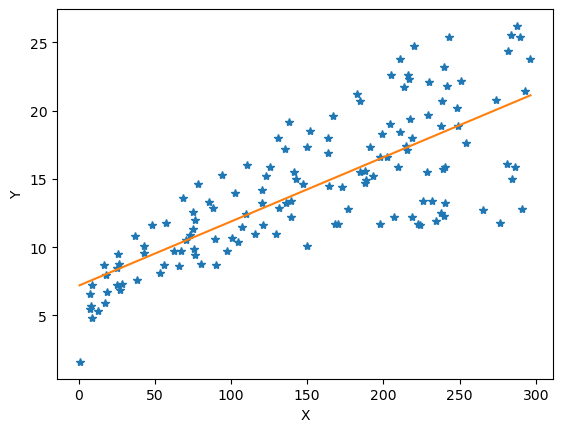

In [77]:
X = df["TV"].values.reshape(-1, 1)
y = df['sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

model = LinearRegression()
model.fit(X_train,y_train)

R2_Factor = model.score(X_train, y_train)

print("R2 Factor:", R2_Factor)

y_pred = model.predict(X_test)

print("MSE:", mean_squared_error(y_pred, y_test))

min_pt = X.min() * model.coef_[0] + model.intercept_
max_pt = X.max() * model.coef_[0] + model.intercept_
plt.plot(X_train, y_train, '*')
plt.plot([X.min(), X.max()], [min_pt, max_pt])
plt.xlabel("X")
plt.ylabel("Y")

plt.show()

### 2. Radio

R2 Factor: 0.34969819733576046
MSE: 20.607018785167416


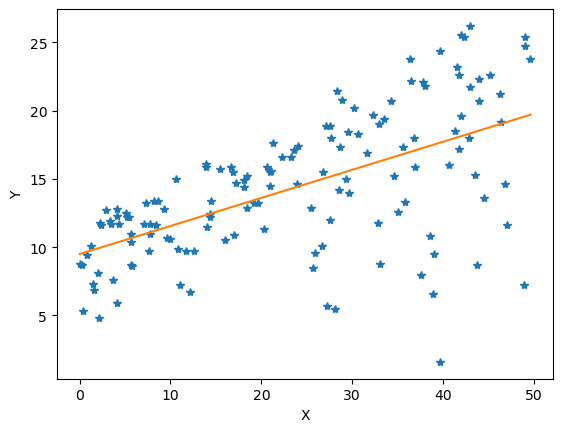

In [78]:
X = df["radio"].values.reshape(-1, 1)
y = df['sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

model = LinearRegression()
model.fit(X_train,y_train)

R2_Factor = model.score(X_train, y_train)

print("R2 Factor:", R2_Factor)

y_pred = model.predict(X_test)

print("MSE:", mean_squared_error(y_pred, y_test))

min_pt = X.min() * model.coef_[0] + model.intercept_
max_pt = X.max() * model.coef_[0] + model.intercept_
plt.plot(X_train, y_train, '*')
plt.plot([X.min(), X.max()], [min_pt, max_pt])
plt.xlabel("X")
plt.ylabel("Y")

plt.show()

### 3. Newspaper

R2 Factor: 0.06487017361800451
MSE: 28.439361834003417


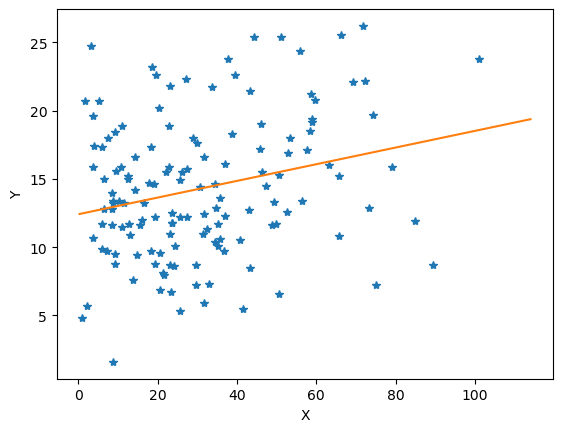

In [79]:
X = df["newspaper"].values.reshape(-1, 1)
y = df['sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

model = LinearRegression()
model.fit(X_train,y_train)

R2_Factor = model.score(X_train, y_train)

print("R2 Factor:", R2_Factor)

y_pred = model.predict(X_test)

print("MSE:", mean_squared_error(y_pred, y_test))

min_pt = X.min() * model.coef_[0] + model.intercept_
max_pt = X.max() * model.coef_[0] + model.intercept_
plt.plot(X_train, y_train, '*')
plt.plot([X.min(), X.max()], [min_pt, max_pt])
plt.xlabel("X")
plt.ylabel("Y")

plt.show()

## Question 10

In [82]:
X = df[["TV", "radio", "newspaper"]].values
y = df['sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

model = LinearRegression()
model.fit(X_train,y_train)

R2_Factor = model.score(X_train, y_train)

print("R2 Factor:", R2_Factor)

y_pred = model.predict(X_test)

print("MSE:", mean_squared_error(y_pred, y_test))



R2 Factor: 0.8856665510409361
MSE: 2.2987166978863773


## Question 11

In [85]:
print(model.coef_)

[ 0.04469599  0.1875657  -0.00032275]


## Question 12

In [90]:
pred = (model.coef_[0] * 149) + (model.coef_[1] * 22) + (model.coef_[2] * 12) + model.intercept_
print(pred)

13.933802164384083


In [92]:
Lred = model.predict([[149, 22, 12]])
print(Lred[0])

13.933802164384083
